# Control modular: línea de transferencia

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/LCS_modular_control_transfer_line.ipynb)
 La línea de
transferencia tiene dos máquinas, $M_1$ y $M_2$, y una unidad de prueba $TU$, unidas por dos
buffers de capacidad 1. La unidad de prueba acepta la pieza, que sale de la línea, o la rechaza y
la devuelve al buffer $B_1$ para que $M_2$ la procese otra vez.

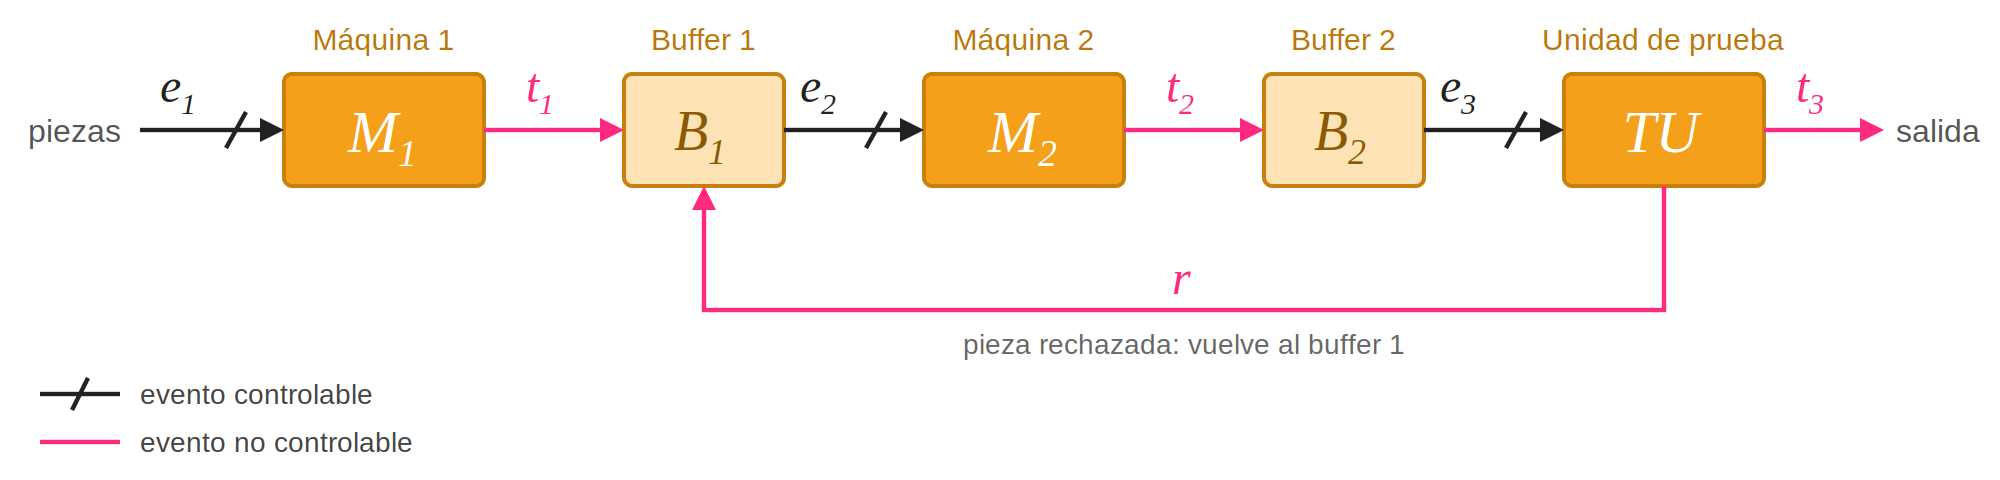

Los eventos controlables se marcan con una rayita sobre el arco y los no controlables van en
color rosado, como en los dibujos de DESlab.

| Evento | Significado | Tipo |
|---|---|---|
| $e_1$ | $M_1$ toma una pieza y empieza a trabajar | controlable |
| $t_1$ | $M_1$ termina y deja la pieza en $B_1$ | no controlable |
| $e_2$ | $M_2$ toma una pieza de $B_1$ | controlable |
| $t_2$ | $M_2$ termina y deja la pieza en $B_2$ | no controlable |
| $e_3$ | $TU$ toma una pieza de $B_2$ para probarla | controlable |
| $t_3$ | $TU$ acepta la pieza, que sale de la línea | no controlable |
| $r$ | $TU$ rechaza la pieza y la devuelve a $B_1$ | no controlable |


In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
DESlab instalado desde el commit 97a7193


In [1]:
from deslab import *

## 1. Planta: máquinas $M_1$, $M_2$ y unidad de prueba $TU$

Cada componente tiene dos estados, $D$ (desocupada, inicial y
marcado) y $O$ (ocupada). Los eventos controlables se dan con `Sigcon`; si se omite, DESlab
considera todos los eventos controlables, y la composición paralela une los conjuntos `Sigcon`.

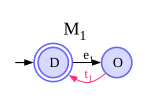

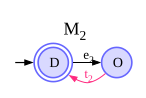

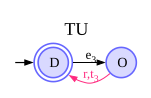

In [2]:
syms('D O B0 B1 e1 t1 e2 t2 e3 t3 r')
tabla = [(e1, 'e_1'), (t1, 't_1'), (e2, 'e_2'), (t2, 't_2'), (e3, 'e_3'), (t3, 't_3')]

M1 = fsa([D, O], [e1, t1], [(D, e1, O), (O, t1, D)], [D], [D], tabla,
         Sigcon=[e1], name='$M_1$')
M2 = fsa([D, O], [e2, t2], [(D, e2, O), (O, t2, D)], [D], [D], tabla,
         Sigcon=[e2], name='$M_2$')
TU = fsa([D, O], [e3, t3, r], [(D, e3, O), (O, t3, D), (O, r, D)], [D], [D], tabla,
         Sigcon=[e3], name='$TU$')
draw(M1, M2, TU)

## 2. Especificaciones: buffers de capacidad 1

$E_1$ cuenta las piezas de $B_1$: $t_1$ y $r$ ponen una pieza y $e_2$ la retira. Como en el estado
$B1$ (lleno) no están $t_1$ ni $r$, prohíbe el desborde, y como en $B0$ (vacío) no está $e_2$,
prohíbe que $M_2$ arranque sin pieza. $E_2$ hace lo mismo con $B_2$, que recibe las piezas de $M_2$
($t_2$) y las entrega a la unidad de prueba ($e_3$).

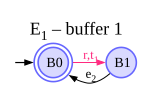

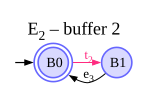

In [3]:
E1 = fsa([B0, B1], [t1, r, e2], [(B0, t1, B1), (B0, r, B1), (B1, e2, B0)], [B0], [B0], tabla,
         Sigcon=[e2], name='$E_1$ -- buffer 1')
E2 = fsa([B0, B1], [t2, e3], [(B0, t2, B1), (B1, e3, B0)], [B0], [B0], tabla,
         Sigcon=[e3], name='$E_2$ -- buffer 2')
draw(E1, E2)

## 3. Supervisor monolítico

La planta es $G = M_1 \parallel M_2 \parallel TU$. En TCT cada especificación se sincroniza con
`ALL` (un estado con autolazos de todos los eventos de $G$) para que tenga el mismo alfabeto que la
planta. En DESlab no hace falta: la composición paralela `//` deja libres los eventos que la
especificación no tiene. Por eso el `supcon(G, ESPEC_ALL)` de TCT se escribe
`supcontrollable(G // E1 // E2, G)`.

Los estados de la composición paralela son tuplas planas: (estado de $M_1$, de $M_2$, de $TU$, de
$B_1$, de $B_2$).

estados de G: 8 | estados del supervisor monolítico: 6


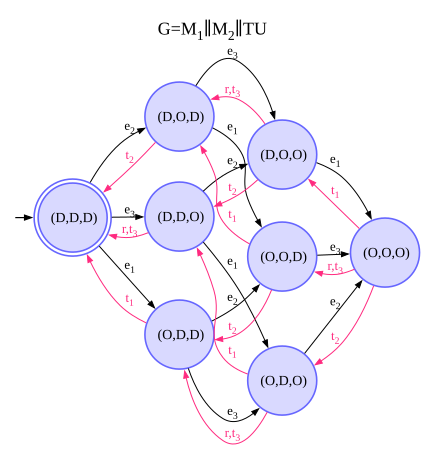

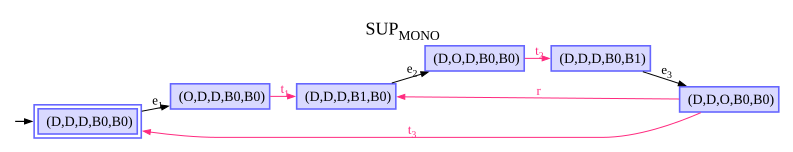

In [ ]:
G = (M1 // M2 // TU).setpar(name='$G = M_1 \\parallel M_2 \\parallel TU$')
SUP_MONO = supcontrollable(G // E1 // E2, G)
SUP_MONO = SUP_MONO.setpar(name='$SUP_{MONO}$', style='rectangle')
print('estados de G:', len(G), '| estados del supervisor monolítico:', len(SUP_MONO))
draw(G, SUP_MONO)

El supervisor monolítico deja entrar una sola pieza a la vez. Con dos piezas en la línea siempre
se puede llegar, por eventos no controlables, a tener $B_1$ y $B_2$ llenos: entonces $M_2$ no puede
tomar la pieza de $B_1$ (al terminar desbordaría $B_2$) y $TU$ no puede tomar la de $B_2$ (si la
rechaza desbordaría $B_1$).

## 4. Supervisores modulares

Cada especificación tiene su propio supervisor, calculado con la misma planta $G$.

estados de SUP1: 3 | estados de SUP2: 2
¿SUP1 y SUP2 son controlables? True True


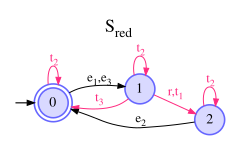

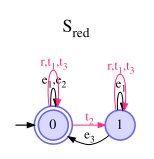

In [8]:
SUP1 = supcontrollable(G // E1, G).setpar(name='$SUP_1$', style='rectangle')
SUP1 = supreduce(SUP1, G)
SUP2 = supcontrollable(G // E2, G).setpar(name='$SUP_2$', style='rectangle')
SUP2 = supreduce(SUP2, G)
print('estados de SUP1:', len(SUP1), '| estados de SUP2:', len(SUP2))
print('¿SUP1 y SUP2 son controlables?', iscontrollable(SUP1, G), iscontrollable(SUP2, G))
draw(SUP1, SUP2)

## 5. ¿Es el supervisor modular igual al monolítico?

Los dos supervisores actúan a la vez, así que el supervisor total es $SUP_1 \parallel SUP_2$.
Sus estados tienen las 4 componentes de los estados de $SUP_1$ seguidas de las 4 de $SUP_2$.

In [9]:
def renombrar(S, f):
    """renombra los estados de S con la función f"""
    return S.renamestates({x: f(x) for x in S.X})

# (M1, M2, TU, B1, M1, M2, TU, B2) -> (M1, M2, TU, B1, B2)
SUP1_SUP2 = renombrar(SUP1 // SUP2, lambda x: x[:4] + x[7:])
SUP1_SUP2 = SUP1_SUP2.setpar(name='$SUP_1 \\parallel SUP_2$', style='rectangle')
print('estados de SUP1 || SUP2:', len(SUP1_SUP2), '| estados de SUP_MONO:', len(SUP_MONO))
print('¿SUP1 || SUP2 es isomorfo a SUP_MONO?', are_isomorhic(SUP1_SUP2, SUP_MONO))

estados de SUP1 || SUP2: 6 | estados de SUP_MONO: 6
¿SUP1 || SUP2 es isomorfo a SUP_MONO? False


## 6. Prueba de no conflicto

La función `nonconflict(G1, G2)` de DESlab es verdadera si desde todo estado alcanzable de
$G_1 \parallel G_2$ se puede llegar a un estado marcado. Con `ALL` como segundo autómata la prueba dice si
$SUP_1 \parallel SUP_2$ es no bloqueante. Los estados bloqueantes se resaltan en naranja.

¿SUP1 y SUP2 son no conflictivos? False
estado bloqueante: (2, 1)


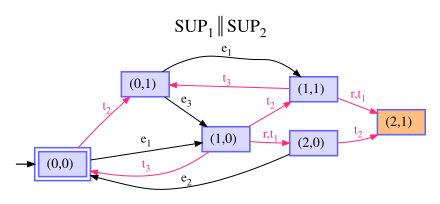

In [10]:
ALL = allevents(G)
print('¿SUP1 y SUP2 son no conflictivos?', nonconflict(SUP1_SUP2, ALL))

bloqueantes = SUP1_SUP2.X - coac(SUP1_SUP2).X
for x in sorted(bloqueantes):
    print('estado bloqueante:', x)
draw(SUP1_SUP2.highlightstates(bloqueantes, color=['orange', 50]))

Los supervisores son conflictivos. Cada uno deja entrar una segunda pieza, porque por separado no
hay problema, pero juntos llegan al estado $(D,D,D,B1,B1)$: $B_1$ y $B_2$ llenos y todo desocupado.
$SUP_2$ no deja que $M_2$ tome la pieza de $B_1$ y $SUP_1$ no deja que $TU$ tome la de $B_2$, así
que el sistema se bloquea. Los otros tres estados naranja llevan inevitablemente a ese.

## 7. Diseño del coordinador

El coordinador $CO$ es el supervisor que hace no bloqueante a $SUP_1 \parallel SUP_2$: se calcula
tomando $SUP_1 \parallel SUP_2$ como planta y como especificación.

In [37]:
CO = supcontrollable(SUP1_SUP2, SUP1_SUP2).setpar(name='coordinador $CO$', style='rectangle')
print('estados del coordinador:', len(CO))
for x in sorted(CO.X):
    deshabilitados = SUP1_SUP2.Gamma(x) - CO.Gamma(x)
    if deshabilitados:
        print(f'en el estado {x} el coordinador deshabilita {sorted(deshabilitados)}')

estados del coordinador: 6
en el estado ('D', 'D', 'D', 'B0', 'B1') el coordinador deshabilita ['e1']
en el estado ('D', 'O', 'D', 'B0', 'B0') el coordinador deshabilita ['e1']


El coordinador solo deshabilita $e_1$: no deja entrar una pieza nueva mientras haya otra en $M_2$ o
en $B_2$. Junto con las restricciones de $SUP_1$, eso impide que haya dos piezas en la línea.

## 8. Verificación: coordinador y supervisores modulares

El sistema controlado por $CO$, $SUP_1$ y $SUP_2$ debe ser controlable, no bloqueante e isomorfo al
supervisor monolítico.

¿TEST es controlable?          True
¿TEST es no bloqueante?        True
¿TEST es isomorfo a SUP_MONO?  True


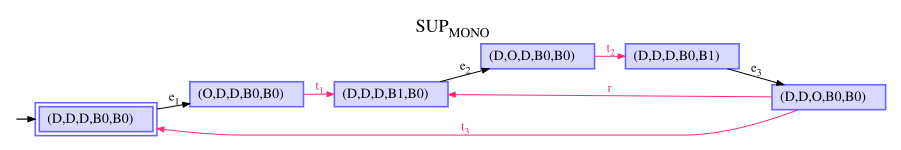

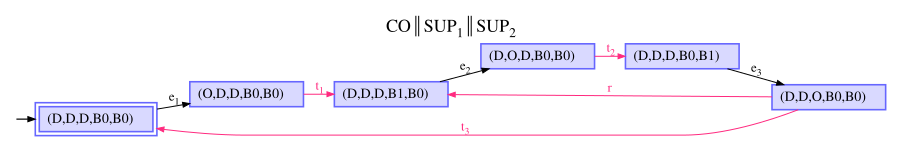

In [44]:
# componentes: las 5 de CO y luego las 4 de SUP1 y las 4 de SUP2, que se repiten
TEST = renombrar(CO // SUP1 // SUP2, lambda x: x[:5])
TEST = TEST.setpar(name='$CO \\parallel SUP_1 \\parallel SUP_2$', style='rectangle')
print('¿TEST es controlable?         ', iscontrollable(TEST, G))
print('¿TEST es no bloqueante?       ', TEST == trim(TEST))
print('¿TEST es isomorfo a SUP_MONO? ', are_isomorhic(TEST, SUP_MONO))
draw(SUP_MONO, TEST)